# 02 - Modélisation et évaluation

Ce notebook compare les modèles du cours sur le **jeu d'entraînement uniquement** (validation croisée stratifiée 5 plis).
Le jeu de test reste intact jusqu'à l'évaluation finale du modèle optimisé.

Plan :
1. Données et découpage
2. Choix des modèles (justification théorique)
3. Sélection de variables et transformation
4. Comparaison des modèles (réglages par défaut)
5. Matrices de confusion, ROC et précision-rappel
6. Compromis biais/variance
7. Synthèse

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import validation_curve

from src.config import FIGURES_DIR, RANDOM_STATE
from src.data import add_binary_target, drop_duplicate_wines, load_wine_data, split_data
from src.evaluate import (
    compare_models,
    default_cv,
    oof_scores,
    plot_confusion_matrices,
    plot_learning_curves,
    plot_pr_curves,
    plot_roc_curves,
)
from src.features import SELECTION_METHODS, selection_table
from src.models import CORE_MODELS, MODEL_NAMES, build_model, model_summary

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)


def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

## 1. Données et découpage

In [2]:
df = drop_duplicate_wines(add_binary_target(load_wine_data()))
X_train, X_test, y_train, y_test = split_data(df)
cv = default_cv()

print(f"Après suppression des doublons : {len(df)} vins")
print(f"Train : {len(X_train)} | Test (non utilisé ici) : {len(X_test)}")
print(f"Part de bons vins - train : {y_train.mean():.3f} | test : {y_test.mean():.3f}")

Après suppression des doublons : 5320 vins
Train : 4256 | Test (non utilisé ici) : 1064
Part de bons vins - train : 0.190 | test : 0.190


## 2. Choix des modèles

In [3]:
model_summary()

,famille,frontière,échelle,atouts,limites
dummy,Référence,Aucune (classe majoritaire),Indifférent,Plancher à battre ; montre le piège de l'accuracy (~81 %),Aucune capacité prédictive
logreg,"Linéaire, discriminatif",Hyperplan,Sensible (standardisation + régularisation),"Coefficients interprétables, probabilités calibrées, rapide",Frontière linéaire ; instable si variables colinéaires (density)
knn,"Non paramétrique, basé sur la distance","Non linéaire, locale",Très sensible (distance euclidienne),Aucune hypothèse de forme ; capte des structures locales,Sensible au bruit et aux variables non pertinentes ; k à valider (biais/vari...
tree,"Non linéaire, règles (Gini/entropie)",Rectangles alignés sur les axes,Indifférent,"Interprétable, robuste aux aberrations, capte les interactions","Variance élevée, sur-apprentissage si profondeur libre"
nb,Probabiliste génératif (Bayes),Quadratique (variances par classe),Indifférent,"Très rapide, peu de données nécessaires","Suppose indépendance et gaussianité : violées ici (corrélations, asymétries)"
svm,"Marge maximale, à noyau",Non linéaire (RBF),Très sensible,"Bon en dimension modérée, marge souple robuste au bruit",Hyperparamètres C et gamma à régler ; coût O(n^2) ; peu interprétable
rf,Ensemble : bagging d'arbres,Non linéaire,Indifférent,Réduit la variance des arbres ; importance des variables ; erreur OOB,Moins interprétable ; modèle volumineux
gb,Ensemble : boosting séquentiel d'arbres,Non linéaire,Indifférent,Réduit le biais ; souvent le meilleur sur données tabulaires,Sensible au bruit et aux hyperparamètres ; plus lent à entraîner


**Logique du choix** : on couvre deux familles. Les modèles **linéaires / paramétriques** (régression logistique, Naive Bayes) sont
rapides et interprétables mais font des hypothèses fortes (frontière linéaire ; indépendance et gaussianité des variables). Les modèles
**non linéaires / non paramétriques** (k-NN, arbre, SVM RBF) captent des frontières complexes mais demandent un contrôle de la complexité.
Les données sont continues, corrélées, asymétriques et bruitées (la note vient de jurys humains) : on s'attend à ce que Naive Bayes souffre
de l'hypothèse d'indépendance, et à ce que k-NN et SVM exigent la standardisation faite dans le pipeline.
La forêt aléatoire et le boosting servent de points de comparaison.

## 3. Sélection de variables et transformation

In [4]:
sel = selection_table(X_train, y_train)
sel.replace({True: "x", False: ""})

,none,vif,l1,rf,mi,n_methods
total sulfur dioxide,x,x,x,x,x,4
alcohol,x,x,x,x,x,4
chlorides,x,x,x,x,x,4
volatile acidity,x,x,x,x,,3
sulphates,x,x,x,,x,3
density,x,,x,x,x,3
citric acid,x,x,x,,x,3
fixed acidity,x,x,x,,,2
residual sugar,x,x,x,,,2
free sulfur dioxide,x,x,x,,,2


In [5]:
# Performance de 3 familles de modèles selon la méthode de sélection (sélection refaite dans chaque pli)
probe = ["logreg", "svm", "rf"]
runs = {}
for method in SELECTION_METHODS:
    runs[method] = compare_models(probe, X_train, y_train, cv=cv, selection=method)
runs["none + log1p"] = compare_models(probe, X_train, y_train, cv=cv, selection="none", log_skewed=True)

sel_perf = pd.concat(runs, names=["selection", "model"])[["f1_mean", "f1_std", "roc_auc_mean", "roc_auc_std"]]
sel_perf.round(3).unstack("model")

f1_mean               f1_std               roc_auc_mean               roc_auc_std              
model         logreg    svm     rf logreg    svm     rf       logreg    svm     rf      logreg    svm     rf
selection                                                                                                   
none           0.532  0.541  0.556  0.026  0.016  0.012        0.828  0.845  0.855       0.021  0.015  0.010
vif            0.530  0.541  0.560  0.022  0.020  0.019        0.824  0.842  0.856       0.021  0.014  0.007
l1             0.531  0.541  0.559  0.024  0.015  0.015        0.826  0.844  0.854       0.019  0.013  0.010
rf             0.516  0.510  0.481  0.027  0.023  0.021        0.811  0.807  0.808       0.024  0.027  0.016
mi             0.517  0.516  0.523  0.020  0.019  0.016        0.805  0.809  0.819       0.023  0.018  0.007
none + log1p   0.538  0.540  0.557  0.019  0.020  0.024        0.832  0.846  0.854       0.021  0.015  0.009

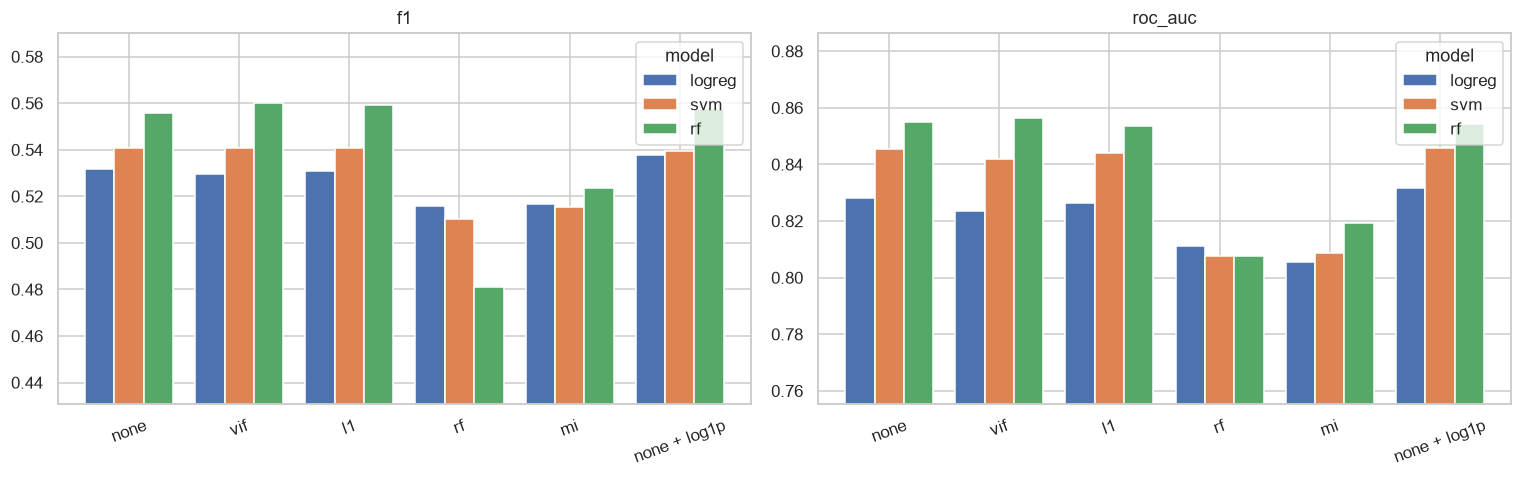

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric in zip(axes, ["f1_mean", "roc_auc_mean"]):
    pivot = sel_perf[metric].unstack("model")[probe]
    pivot.plot.bar(ax=ax, rot=20, width=0.8)
    ax.set(title=metric.replace("_mean", ""), xlabel="", ylabel="")
    ax.set_ylim(pivot.values.min() - 0.05, pivot.values.max() + 0.03)
plt.tight_layout()
save(fig, "08_selection_comparison")
plt.show()

**Lecture** :
- Les méthodes **VIF** (retire `density`) et **L1** (retire seulement `type_white`) donnent des performances **identiques** à l'absence de
  sélection (différences ≤ 0,005, inférieures à l'écart-type entre plis) : on peut réduire la multicolinéarité sans rien perdre.
- L'**importance par forêt** (seuil = moyenne) et l'**information mutuelle** (top 6) éliminent trop de variables et **dégradent** nettement
  F1 et ROC-AUC. L'information mutuelle, purement univariée, ignore les variables utiles seulement en combinaison (ex. `volatile acidity`).
- La transformation `log1p` des variables asymétriques n'apporte qu'un gain marginal pour la régression logistique (F1 0,538 contre 0,532)
  et rien pour la forêt ; elle est conservée comme option à valider en phase d'optimisation.
- **Choix retenu** : pas de sélection destructive ; `vif` ou `l1` comme options à comparer lors de la recherche d'hyperparamètres.

## 4. Comparaison des modèles (réglages par défaut)

In [7]:
results = compare_models(MODEL_NAMES, X_train, y_train, cv=cv)

def fmt(r, m):
    return r.apply(lambda row: f"{row[m + '_mean']:.3f} ± {row[m + '_std']:.3f}", axis=1)

table = pd.DataFrame({m: fmt(results, m) for m in ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]})
table["f1 train"] = results["f1_train"].round(3)
table

,accuracy,precision,recall,f1,roc_auc,average_precision,f1 train
dummy,0.810 ± 0.001,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.190 ± 0.001,0.000
logreg,0.737 ± 0.024,0.403 ± 0.028,0.784 ± 0.034,0.532 ± 0.026,0.828 ± 0.021,0.509 ± 0.039,0.537
knn,0.830 ± 0.014,0.567 ± 0.050,0.434 ± 0.037,0.491 ± 0.041,0.799 ± 0.013,0.469 ± 0.035,0.635
tree,0.789 ± 0.011,0.442 ± 0.023,0.429 ± 0.028,0.435 ± 0.018,0.651 ± 0.011,0.298 ± 0.012,1.000
nb,0.745 ± 0.013,0.395 ± 0.020,0.646 ± 0.038,0.490 ± 0.026,0.769 ± 0.020,0.446 ± 0.022,0.490
svm,0.740 ± 0.016,0.407 ± 0.017,0.808 ± 0.020,0.541 ± 0.016,0.845 ± 0.015,0.539 ± 0.044,0.585
rf,0.826 ± 0.007,0.540 ± 0.019,0.574 ± 0.028,0.556 ± 0.012,0.855 ± 0.010,0.592 ± 0.017,0.997
gb,0.833 ± 0.006,0.610 ± 0.035,0.340 ± 0.037,0.434 ± 0.029,0.843 ± 0.015,0.539 ± 0.036,0.597


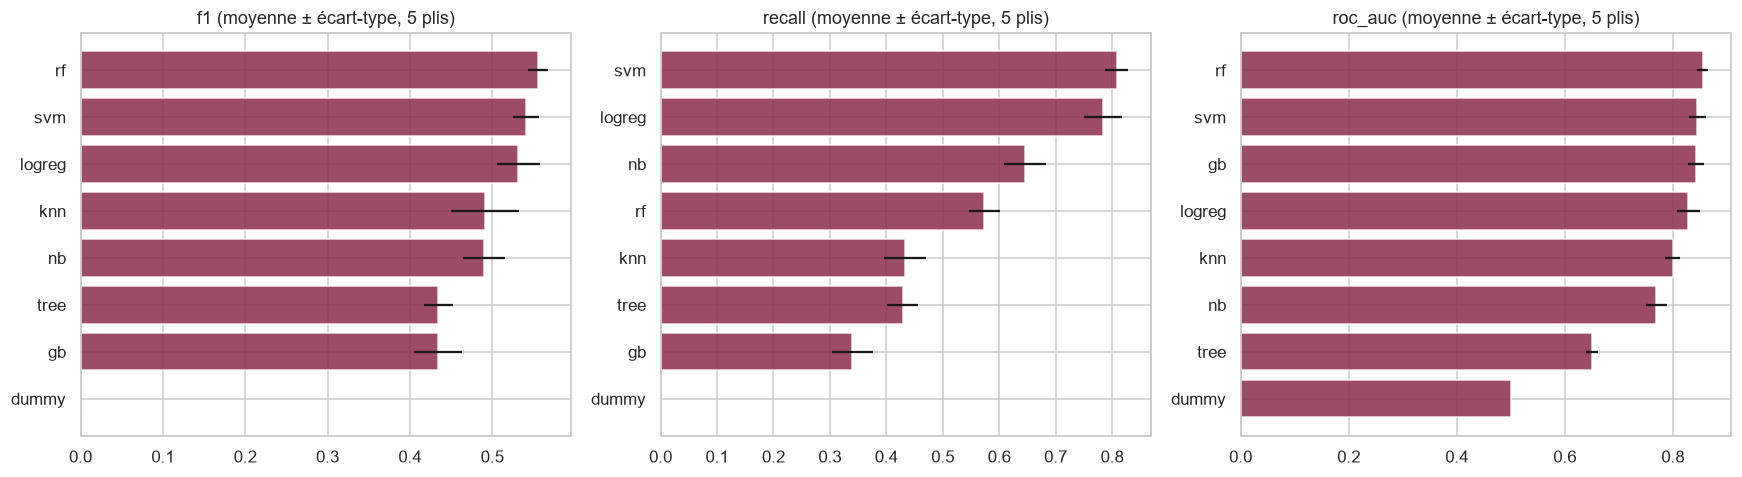

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=False)
for ax, m in zip(axes, ["f1", "recall", "roc_auc"]):
    order = results[f"{m}_mean"].sort_values()
    ax.barh(order.index, order.values, xerr=results.loc[order.index, f"{m}_std"], color="#8c2d4b", alpha=0.85)
    ax.set(title=f"{m} (moyenne ± écart-type, 5 plis)")
plt.tight_layout()
save(fig, "09_models_cv_comparison")
plt.show()

**Lecture** (seuil de décision par défaut) :
- Le dummy atteint 81 % d'accuracy avec un rappel nul : l'**accuracy est trompeuse** sur des classes 80/20.
- **Forêt aléatoire** : meilleurs F1 (0,556) et ROC-AUC (0,855), mais c'est aussi un des modèles qui sur-apprend le plus (F1 train ≈ 1).
- **SVM RBF** et **régression logistique** (pondérées par classe) ont le meilleur rappel (0,81 et 0,78) au prix d'une précision d'environ 0,40 ;
  leur F1 (0,54 et 0,53) est proche de celui de la forêt avec un ROC-AUC de 0,845 et 0,828.
- **Boosting** et **k-NN** ont la meilleure précision (0,61 et 0,57) mais un faible rappel (0,34 et 0,43) : ils prédisent peu de bons vins.
  Leur ROC-AUC (0,843 pour le boosting) montre que le classement des vins est bon ; c'est le **seuil** qui est mal placé, ce que la phase
  d'optimisation corrigera.
- **Arbre seul** : le plus mauvais modèle non trivial (ROC-AUC 0,651), typique d'une variance élevée.
- **Naive Bayes** (F1 0,49, ROC-AUC 0,77) est pénalisé par la corrélation des variables, conformément à son hypothèse d'indépendance.
- Les écarts entre SVM, régression logistique et forêt (≈ 0,02 de F1) sont du même ordre que les écarts-types : ils ne sont pas tranchés avant
  l'optimisation.

## 5. Matrices de confusion, ROC et précision-rappel

In [9]:
# Prédictions hors-pli : chaque vin est noté par un modèle qui ne l'a pas vu à l'entraînement
models = {n: build_model(n) for n in MODEL_NAMES if n != "dummy"}
oof = {n: oof_scores(m, X_train, y_train, cv=cv) for n, m in models.items()}
scores = {n: s for n, (s, _) in oof.items()}
preds = {n: (s > thr).astype(int) for n, (s, thr) in oof.items()}

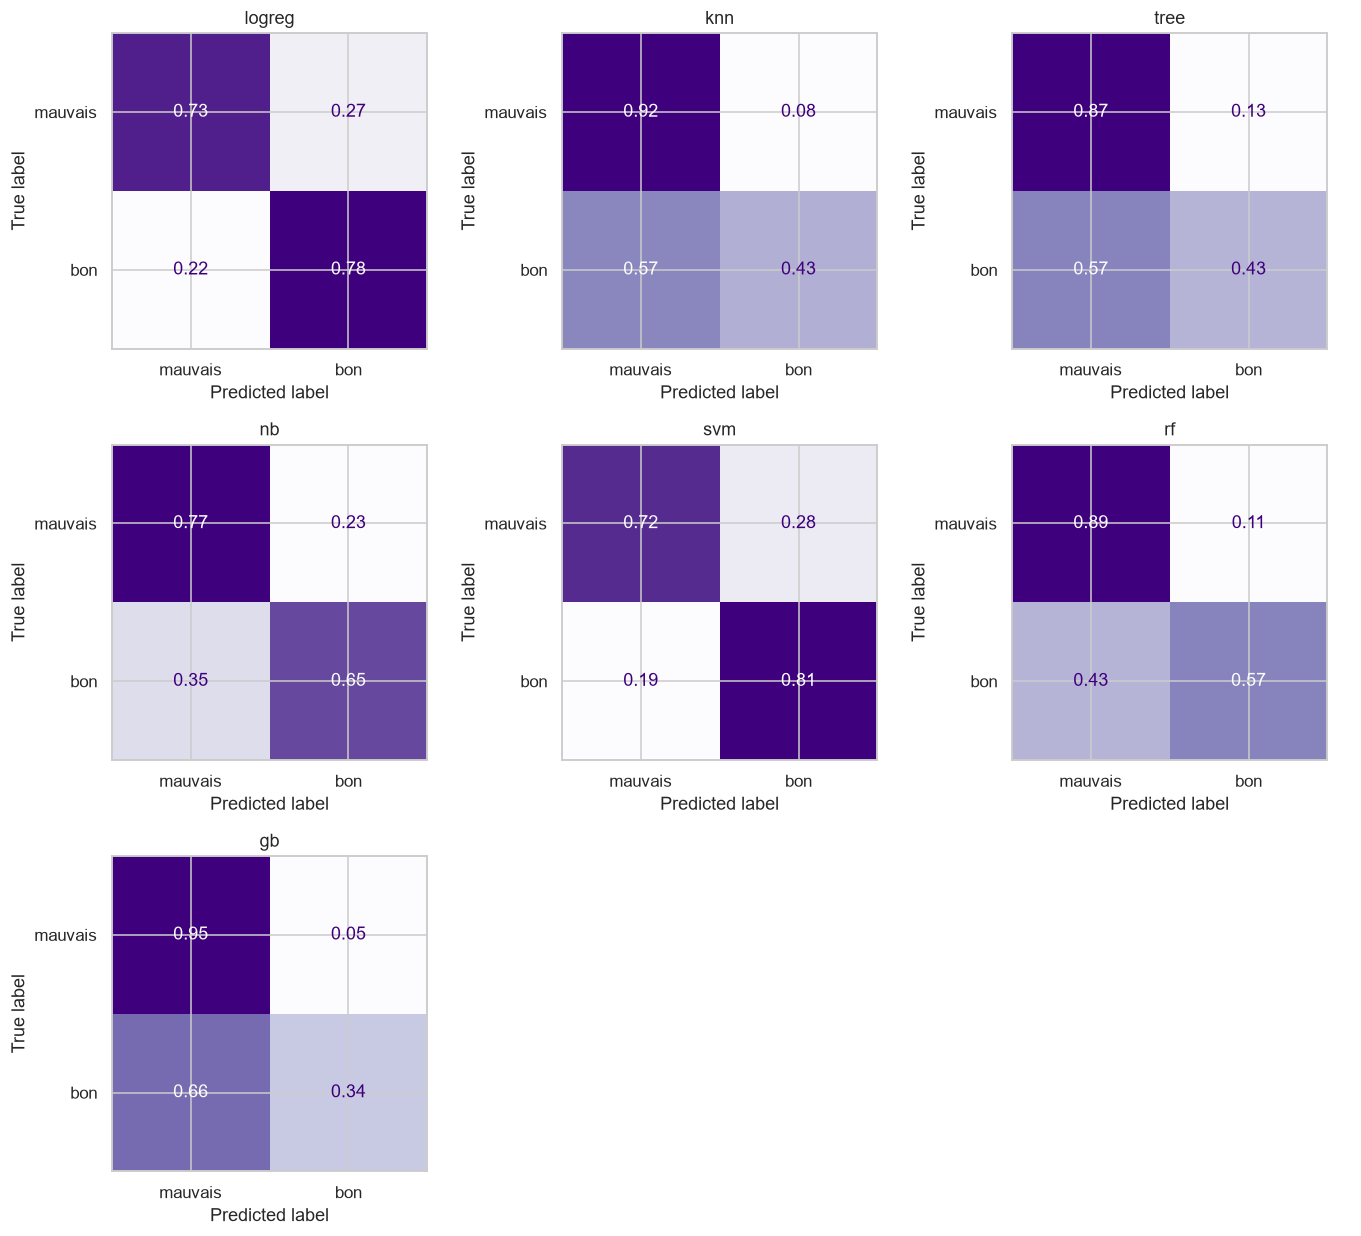

In [10]:
fig = plot_confusion_matrices(y_train, preds, normalize="true")
save(fig, "10_confusion_matrices")
plt.show()

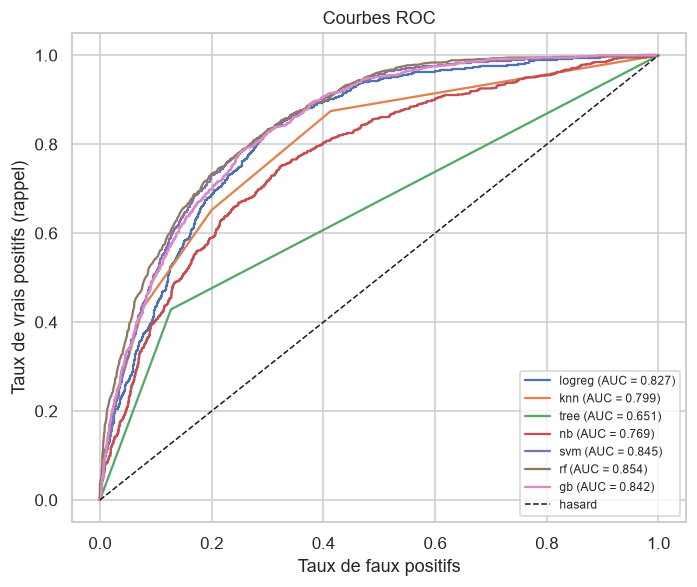

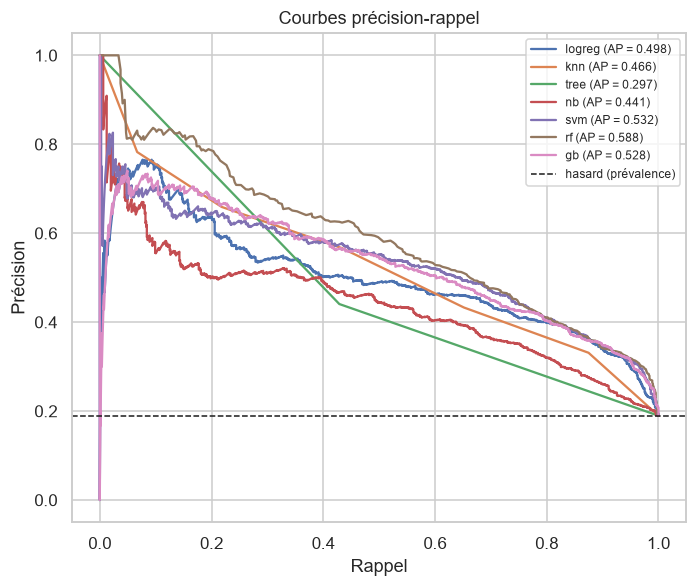

In [11]:
fig = plot_roc_curves(y_train, scores)
save(fig, "11_roc_curves")
plt.show()
fig = plot_pr_curves(y_train, scores)
save(fig, "12_pr_curves")
plt.show()

**Lecture** :
- Les matrices de confusion (normalisées par ligne) montrent le compromis rappel / spécificité : SVM (81 % des bons vins détectés, 72 % des
  mauvais bien classés) et régression logistique (78 % / 73 %) privilégient le rappel ; boosting (34 % / 95 %) et k-NN (43 % / 92 %)
  privilégient la spécificité.
- Les courbes **ROC et PR ne dépendent pas du seuil** : elles classent la forêt (AUC 0,855, AP 0,59), le SVM et le boosting en tête,
  la régression logistique juste derrière, k-NN et Naive Bayes plus bas, l'arbre en dernier.
- Pour un problème déséquilibré, la **courbe PR** est plus informative que la ROC : l'AP de la forêt (0,59) est très au-dessus de la
  prévalence (0,19).

## 6. Compromis biais/variance

In [12]:
gap = results[["f1_train", "f1_mean", "f1_gap"]].round(3)
gap.columns = ["F1 train", "F1 CV", "écart"]
gap.sort_values("écart", ascending=False)

,F1 train,F1 CV,écart
tree,1.000,0.435,0.565
rf,0.997,0.556,0.441
gb,0.597,0.434,0.163
knn,0.635,0.491,0.144
svm,0.585,0.541,0.044
logreg,0.537,0.532,0.005
nb,0.490,0.490,0.001
dummy,0.000,0.000,0.000


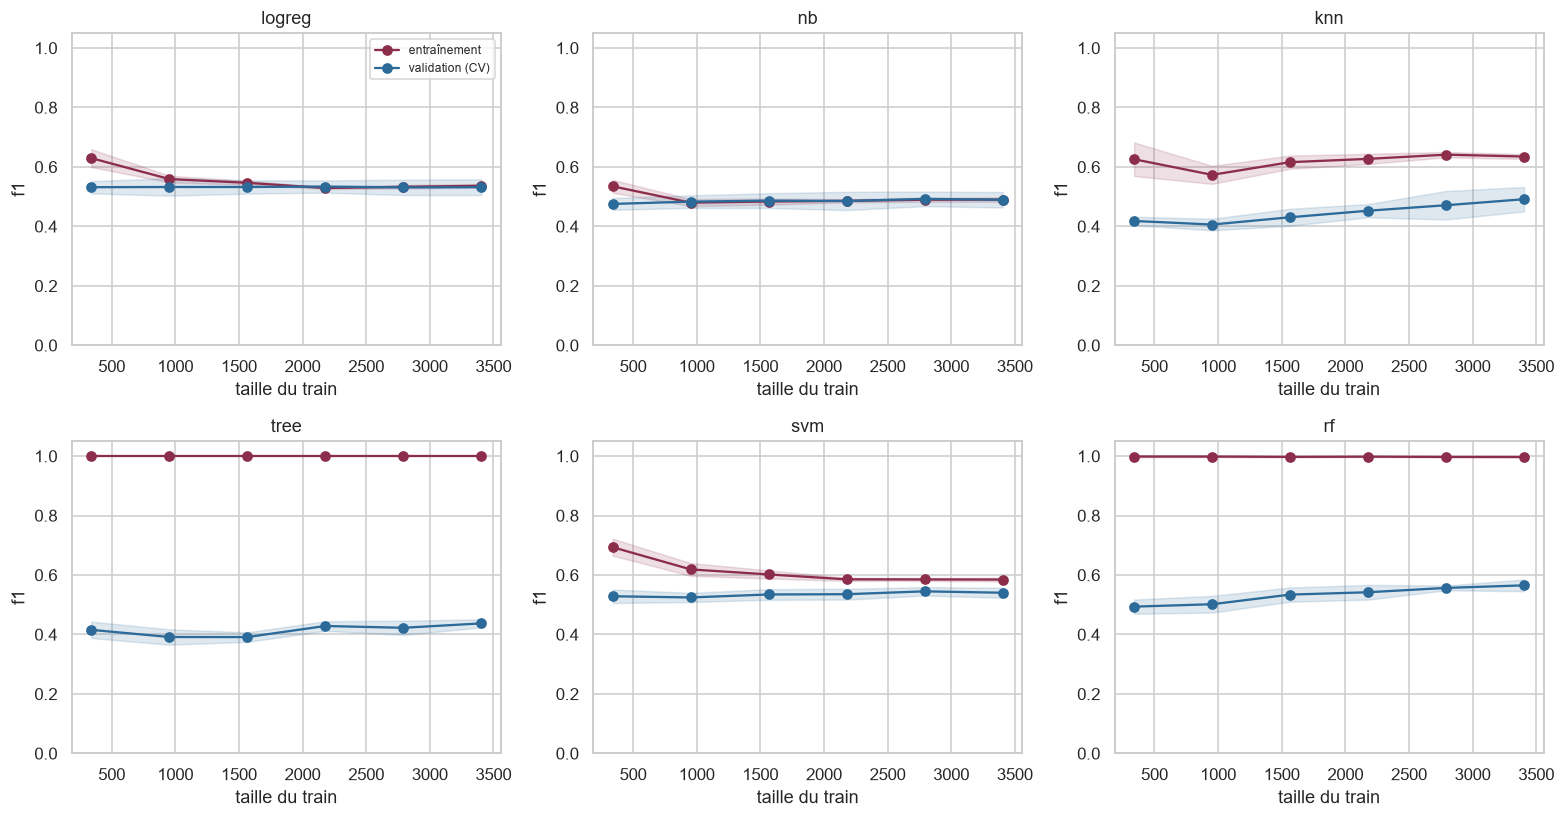

In [13]:
diag = {n: build_model(n) for n in ["logreg", "nb", "knn", "tree", "svm", "rf"]}
fig = plot_learning_curves(diag, X_train, y_train, scoring="f1", cv=cv)
save(fig, "13_learning_curves")
plt.show()

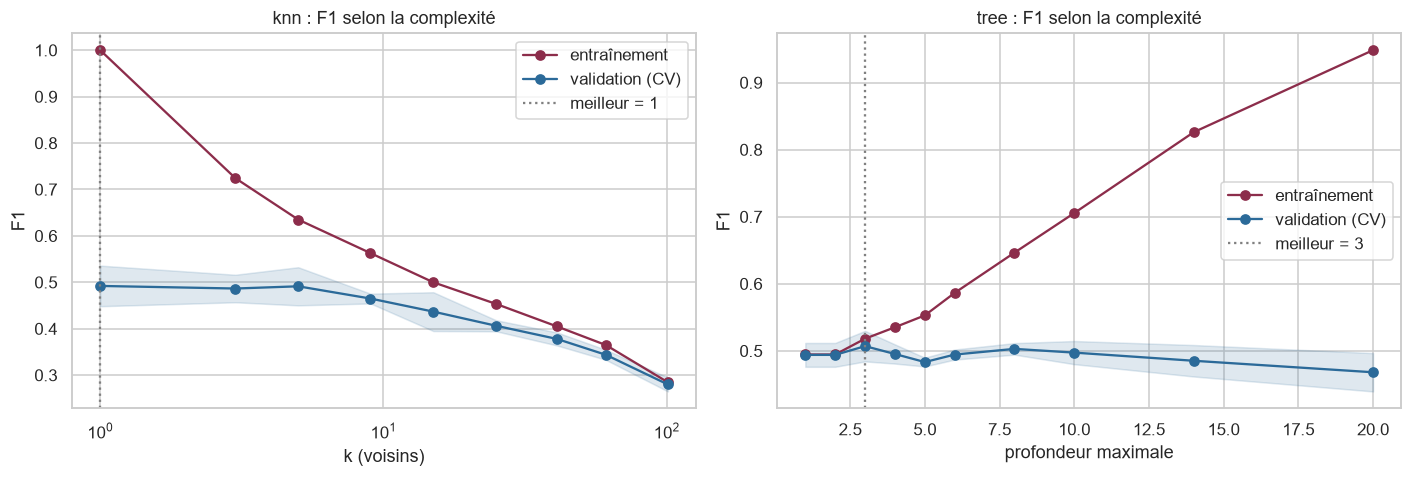

In [14]:
# Complexité vs erreur : k pour k-NN, profondeur pour l'arbre
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
configs = [
    ("knn", "clf__n_neighbors", [1, 3, 5, 9, 15, 25, 41, 61, 101], "k (voisins)"),
    ("tree", "clf__max_depth", [1, 2, 3, 4, 5, 6, 8, 10, 14, 20], "profondeur maximale"),
]
for ax, (name, param, grid, label) in zip(axes, configs):
    tr, va = validation_curve(build_model(name), X_train, y_train, param_name=param, param_range=grid,
                              cv=cv, scoring="f1", n_jobs=-1)
    ax.plot(grid, tr.mean(axis=1), "o-", color="#8c2d4b", label="entraînement")
    ax.plot(grid, va.mean(axis=1), "o-", color="#2b6a99", label="validation (CV)")
    ax.fill_between(grid, va.mean(axis=1) - va.std(axis=1), va.mean(axis=1) + va.std(axis=1), color="#2b6a99", alpha=0.15)
    ax.set(title=f"{name} : F1 selon la complexité", xlabel=label, ylabel="F1")
    if name == "knn":
        ax.set_xscale("log")
    best = grid[int(va.mean(axis=1).argmax())]
    ax.axvline(best, color="grey", ls=":", label=f"meilleur = {best}")
    ax.legend()
plt.tight_layout()
save(fig, "14_complexity_curves")
plt.show()

**Lecture** :
- **Arbre** et **forêt** : F1 d'entraînement ≈ 1 contre 0,44 et 0,56 en validation : **variance élevée** (sur-apprentissage). Les courbes
  d'apprentissage ne se rejoignent pas ; plus de données ou plus de régularisation (profondeur, `min_samples_leaf`) aideraient. La profondeur de
  l'arbre est le levier : la validation est la meilleure vers une profondeur de 3 (F1 ≈ 0,51), puis se dégrade alors que l'entraînement monte.
- **Régression logistique** et **Naive Bayes** : courbes d'entraînement et de validation **confondues** et basses : **biais élevé**
  (sous-apprentissage). Ajouter des données n'aidera pas ; il faut des modèles plus expressifs.
- **SVM RBF** : bon compromis (écart train/CV ≈ 0,04), courbes proches de la convergence.
- **k-NN** : écart notable (0,64 contre 0,49). Dans la courbe de complexité, le F1 de validation baisse quand k augmente, car avec un vote majoritaire
  non pondéré un grand k prédit presque toujours la classe majoritaire (le rappel s'effondre) ; le bon k dépend donc du seuil et de la métrique
  optimisés, ce qui sera traité en phase 5.

**Modèle le plus performant à ce stade, selon le compromis biais/variance** : le **SVM RBF** et la **forêt aléatoire** sont en tête. Le SVM est
le mieux équilibré (peu de variance, F1 et ROC-AUC élevés), la forêt est légèrement meilleure en ROC-AUC et F1 mais sur-apprend davantage.

## 7. Synthèse et suite

| Question | Réponse |
|---|---|
| Métrique principale | F1 de la classe « bon » et ROC-AUC / PR-AUC (pas l'accuracy) |
| Sélection de variables | `vif` ou `l1` sans perte ; importance par forêt (seuil moyen) et information mutuelle (top 6) dégradent |
| Meilleurs candidats | SVM RBF, forêt aléatoire, puis régression logistique et boosting |
| Modèles en difficulté | Arbre seul (variance), Naive Bayes (hypothèse d'indépendance), régression logistique (biais) |
| Piste d'amélioration | Réglage des hyperparamètres (Grid / Random Search) et du **seuil de décision** |

**Phase 5** : optimisation par Grid Search (modèles à peu d'hyperparamètres) et Random Search (SVM, forêt, boosting), puis évaluation unique
sur le jeu de test.